# Detecting Outliers with IQR and Boxplots


**Learning goals**
- Explain Q1, the median, Q3 and IQR.
- Calculate the 1.5 × IQR fences and identify flagged observations.
- Read a real boxplot and distinguish fences from whiskers.


## 1. Import the libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({'figure.figsize': (9, 4), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, RED = '#2463a6', '#d44335'


## 2. Generate reproducible data
Following the original lesson, add independent normal and uniform random values. The result is **not exactly normally distributed**. The IQR rule does not require a normal distribution, although skewness and tail shape affect its interpretation.

,Data
0,-16.395378
1,-21.213600
2,-7.222599
3,16.511994
4,-34.637052


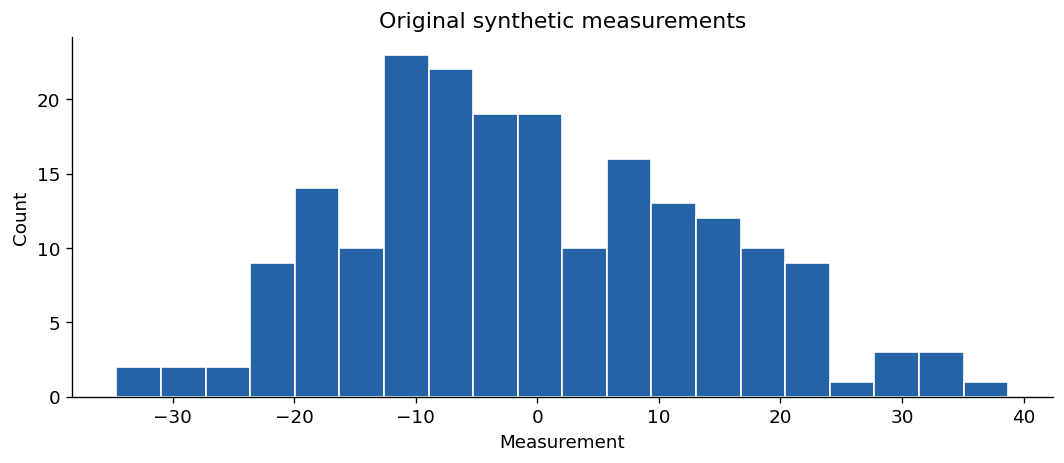

In [ ]:
rng = np.random.default_rng(42)
values = rng.normal(0, 10, 200) + rng.uniform(-20, 20, 200)
original = pd.DataFrame({'Data': values})
display(original.head())
fig, ax = plt.subplots()
ax.hist(original['Data'], bins=20, color=BLUE, edgecolor='white')
ax.set(title='Original synthetic measurements', xlabel='Measurement', ylabel='Count')
plt.tight_layout()
plt.show()

## 3. Preserve the original and insert extreme values
Use `original.copy()` to create an independent DataFrame. Assigning `df = original` would make both names refer to the same object. We use −100 and 180 as clear injected extremes; −40 is not necessarily an outlier under an IQR rule.

In [ ]:
df = original.copy()
df.loc[50, 'Data'] = -100
df.loc[90, 'Data'] = 180
display(pd.DataFrame({'Original': original.loc[[50, 90], 'Data'],
                      'Modified': df.loc[[50, 90], 'Data']}))

,Original,Modified
50,-7.642311,-100.0
90,20.396849,180.0


## 4. Calculate quartiles and fences
- **Q1:** 25th percentile.
- **Median (Q2):** 50th percentile.
- **Q3:** 75th percentile.
- **IQR:** width of the middle 50% of the distribution.

$$IQR=Q3-Q1$$
$$L=Q1-1.5\,IQR,\qquad U=Q3+1.5\,IQR$$

Flag $x<L$ or $x>U$. Values exactly on the fences are not flagged. The multiplier 1.5 is a conventional screening choice, not a universal law.

We calculate the quartiles **after changing the data**, so the table, flags and boxplot describe the same dataset. pandas uses linear interpolation for these quantiles by default.

In [ ]:
Q1 = df['Data'].quantile(0.25)
median = df['Data'].median()
Q3 = df['Data'].quantile(0.75)
IQR = Q3 - Q1
multiplier = 1.5
lower = Q1 - multiplier * IQR
upper = Q3 + multiplier * IQR
df['outlier'] = (df['Data'] < lower) | (df['Data'] > upper)
display(pd.Series({'Q1': Q1, 'Median': median, 'Q3': Q3, 'IQR': IQR,
                   'Lower fence': lower, 'Upper fence': upper}).round(3))
display(df.loc[df['outlier']])
print(f"Flagged: {df['outlier'].sum()} / {len(df)}")

Q1            -10.572
Median         -2.283
Q3             10.268
IQR            20.839
Lower fence   -41.831
Upper fence    41.527
dtype: float64

,Data,outlier
50,-100.0,True
90,180.0,True


Flagged: 2 / 200


## 5. Read a real boxplot
The box spans Q1 to Q3; the line inside the box is the median. With `whis=1.5`, the whiskers end at the lowest and highest **observed values within the fences**, not necessarily at the fences themselves. Points beyond the whiskers are plotted individually as fliers.

The dashed orange lines below are the calculated fences; the solid whisker caps mark actual data values.

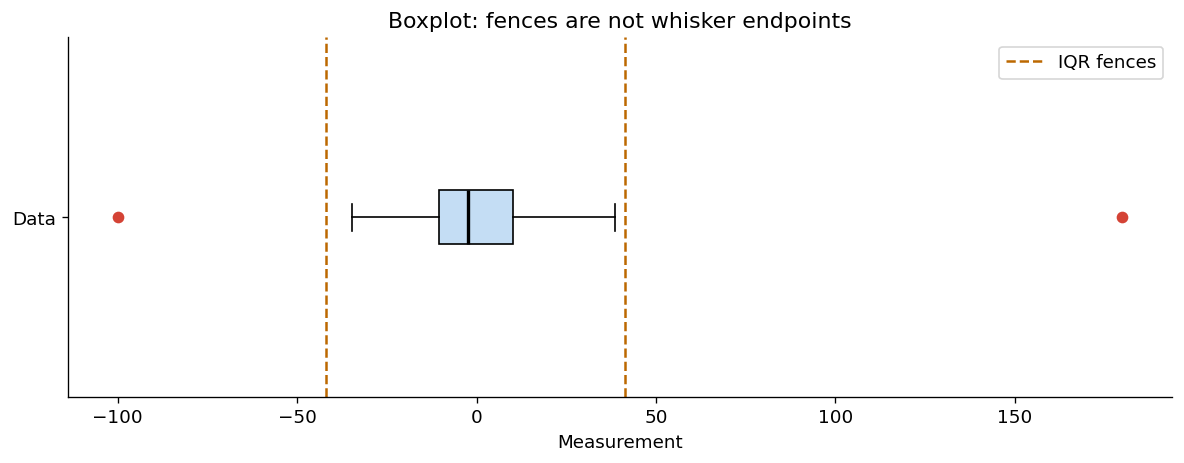

,Lower,Upper
Calculated fence,-41.831,41.527
Observed whisker endpoint,-34.637,38.737


In [ ]:
inside = df.loc[~df['outlier'], 'Data']
whisker_low, whisker_high = inside.min(), inside.max()
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot(df['Data'], vert=False, whis=multiplier, patch_artist=True,
           boxprops={'facecolor': '#c4ddf4'},
           medianprops={'color': 'black', 'linewidth': 2},
           flierprops={'marker': 'o', 'markerfacecolor': RED, 'markeredgecolor': RED})
ax.axvline(lower, color='#bc6800', linestyle='--', label='IQR fences')
ax.axvline(upper, color='#bc6800', linestyle='--')
ax.set(title='Boxplot: fences are not whisker endpoints', xlabel='Measurement',
       yticks=[1], yticklabels=['Data'])
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Lower': [lower, whisker_low], 'Upper': [upper, whisker_high]},
                      index=['Calculated fence', 'Observed whisker endpoint']).round(3))

## 6. Locate the flagged observations
Observation index is an identifier here, not a time axis.

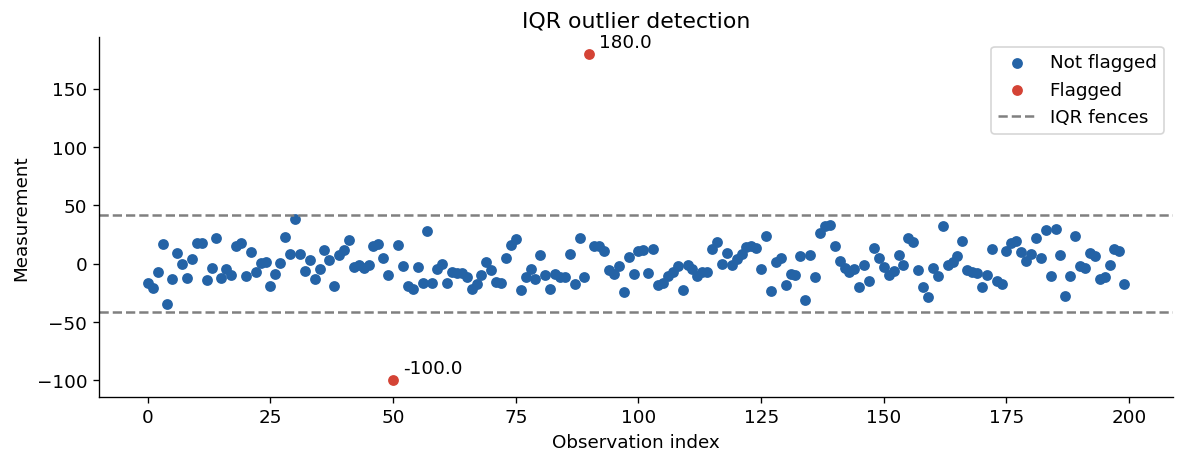

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
for flag, color, label in [(False, BLUE, 'Not flagged'), (True, RED, 'Flagged')]:
    subset = df.loc[df['outlier'] == flag]
    ax.scatter(subset.index, subset['Data'], color=color, label=label, s=30)
ax.axhline(lower, color='gray', linestyle='--', label='IQR fences')
ax.axhline(upper, color='gray', linestyle='--')
for index, row in df.loc[df['outlier']].iterrows():
    ax.annotate(f"{row['Data']:.1f}", (index, row['Data']), xytext=(6, 4),
                textcoords='offset points')
ax.set(title='IQR outlier detection', xlabel='Observation index', ylabel='Measurement')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

## 7. Is −40 necessarily an outlier?
Evaluate some candidate values against the **fixed fences calculated above**. This does not append them to the dataset or recalculate the quartiles.

In [ ]:
candidates = pd.DataFrame({'Candidate': [-100.0, -40.0, 0.0, 180.0]})
candidates['Flagged using fixed fences'] = ((candidates['Candidate'] < lower) |
                                            (candidates['Candidate'] > upper))
display(candidates)

,Candidate,Flagged using fixed fences
0,-100.0,True
1,-40.0,False
2,0.0,False
3,180.0,True


## 8. Compare before and after
Both boxplots use `whis=1.5` and a shared measurement scale. Each boxplot calculates its own quartiles from its own dataset. The quartiles change much less than the extremes in this example.

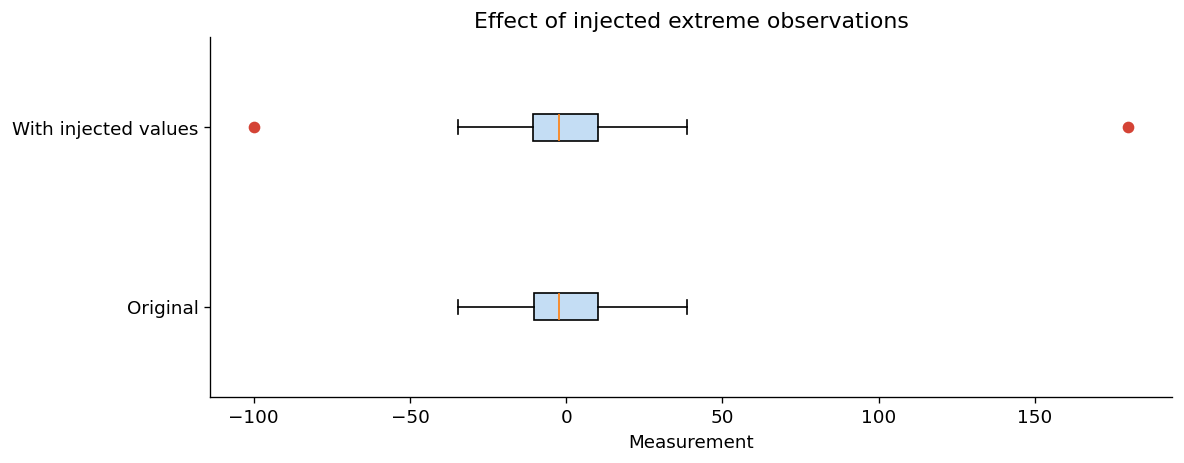

,Original,Modified
0.25,-10.420,-10.572
0.50,-2.283,-2.283
0.75,10.268,10.268


In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([original['Data'], df['Data']], vert=False, whis=1.5,
           patch_artist=True, boxprops={'facecolor': '#c4ddf4'},
           flierprops={'marker': 'o', 'markerfacecolor': RED, 'markeredgecolor': RED})
ax.set(yticks=[1, 2], yticklabels=['Original', 'With injected values'],
       xlabel='Measurement', title='Effect of injected extreme observations')
plt.tight_layout()
plt.show()
display(pd.DataFrame({'Original': original['Data'].quantile([.25, .5, .75]),
                      'Modified': df['Data'].quantile([.25, .5, .75])}).round(3))

## 9. Sensitivity to the multiplier
A larger multiplier widens the fences. For fixed data and quartiles, it cannot increase the number flagged.

In [ ]:
rows = []
for k in [1.0, 1.5, 2.0, 3.0]:
    low, high = Q1 - k * IQR, Q3 + k * IQR
    flags = (df['Data'] < low) | (df['Data'] > high)
    rows.append({'Multiplier': k, 'Lower fence': low, 'Upper fence': high,
                 'Number flagged': int(flags.sum())})
display(pd.DataFrame(rows).round(3))

,Multiplier,Lower fence,Upper fence,Number flagged
0,1.0,-31.411,31.107,7
1,1.5,-41.831,41.527,2
2,2.0,-52.250,51.946,2
3,3.0,-73.090,72.785,2


## 10. Handling flags and practice
A flag does not prove an error. Investigate before correcting or removing observations. The following filtering example is appropriate for illustrating removal of known synthetic extremes; it preserves the full `df` and does not restore the original replaced values.

In [ ]:
filtered = df.loc[~df['outlier'], ['Data']].copy()
print(f'Before: {len(df)} rows; after illustrative filtering: {len(filtered)} rows')

Before: 200 rows; after illustrative filtering: 198 rows




**Takeaway:** IQR flags values outside quartile-based fences. A boxplot displays quartiles, observed whisker endpoints and individually plotted fliers.
